# IMDB Sentiment Analysis: RNN vs LSTM vs GRU vs BiLSTM

Binary sentiment classification of movie reviews with recurrent networks, compared against a **TF-IDF + Logistic Regression** baseline.

**Models:** Simple RNN, LSTM, GRU, Bidirectional LSTM (same Embedding → recurrent layer → Dropout → Dense architecture, same hyperparameters and callbacks).
**Dataset:** IMDB (Keras): 25,000 training and 25,000 test reviews, perfectly balanced.
**Metrics:** Accuracy, Precision, Recall, F1, training time, confusion matrices and learning curves.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

In [2]:

import re
import random
import tensorflow as tf
from tensorflow.keras.layers import Bidirectional
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

## 2. Configuration
All hyperparameters live here so the comparison between models is fair.

In [3]:
VOCAB_SIZE = 10_000
MAX_LENGTH = 200
EMBEDDING_DIM = 128
RNN_UNITS = 64
BATCH_SIZE = 64
EPOCHS = 15
RANDOM_STATE = 42

## 3. Reproducibility
Fixed random seeds for Python, NumPy and TensorFlow. (Seeds make runs similar, but GPU training is not fully deterministic, so neural-network results can still vary slightly between runs.)

In [4]:

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

## 4. Load the dataset
Reviews come pre-encoded as word IDs; only the 10,000 most frequent words are kept.

In [5]:
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 25000
Testing samples: 25000


## 5. Explore the data
A first look at an encoded review and the class balance.

In [6]:
print("First encoded review:")
print(X_train[0])

print("\nLabel:")
print(y_train[0])

First encoded review:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]

Label:
1


In [7]:
print("Number of positive reviews:", np.sum(y_train == 1))
print("Number of negative reviews:", np.sum(y_train == 0))

Number of positive reviews: 12500
Number of negative reviews: 12500


## 6. Review length distribution
Used to choose a reasonable `MAX_LENGTH` for padding.

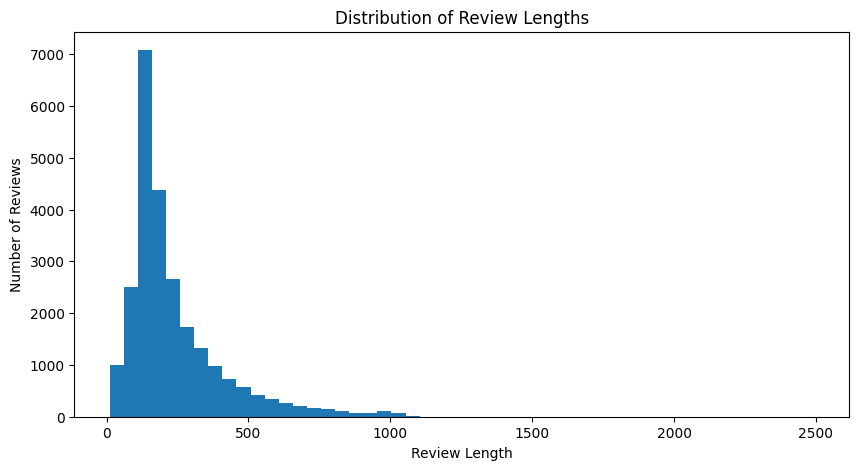

In [8]:
train_lengths = [len(x) for x in X_train]

plt.figure(figsize=(10, 5))
plt.hist(train_lengths, bins=50)
plt.xlabel("Review Length")
plt.ylabel("Number of Reviews")
plt.title("Distribution of Review Lengths")
plt.show()

## 7. Decode reviews back to text
Keras reserves indices 0 (`<PAD>`), 1 (`<START>`) and 2 (`<UNK>`), so word indices are shifted by +3.

In [9]:
word_index = imdb.get_word_index()

reverse_word_index = {
    value + 3: key
    for key, value in word_index.items()
}
reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [10]:
def decode_review(encoded_review):
    return " ".join(
        reverse_word_index.get(i, "?")
        for i in encoded_review
    )

print(decode_review(X_train[0]))

<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNK> to the two little boy's that played the <UNK> of norman and paul they were just brilliant children are often left out of the <UNK> list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for wha

## 8. Padding
Every review is padded/truncated to 200 tokens with **`pre`** padding and truncating.

> An earlier run used `post` padding, and Simple RNN and GRU stayed at about 51% accuracy (chance level): the recurrent state had to cross many padding tokens before the prediction, and truncating from the end removed the part of the review that usually holds the verdict.

In [11]:
X_train_pad = pad_sequences(
    X_train,
    maxlen=MAX_LENGTH,
    padding="pre",
    truncating="pre",
)
X_test_pad = pad_sequences(
    X_test,
    maxlen=MAX_LENGTH,
    padding="pre",
    truncating="pre",
)

In [12]:
print("Before padding:", len(X_train[0]))
print("After padding:", len(X_train_pad[0]))
print(X_train_pad.shape)
print(X_test_pad.shape)

Before padding: 218
After padding: 200
(25000, 200)
(25000, 200)


## 9. Simple RNN
Architecture: Embedding → SimpleRNN → Dropout → Dense (sigmoid).

In [13]:
def build_rnn_model():
    model = Sequential([
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIM,
        ),
        SimpleRNN(RNN_UNITS),
        Dropout(0.5),
        Dense(1, activation="sigmoid"),
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [14]:
rnn_model = build_rnn_model()
rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### Training
EarlyStopping on `val_loss` (patience 5, best weights restored); a fresh callback is created for every model.

In [15]:
def make_early_stopping():
    return EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
    )

start_time = time.time()
rnn_history = rnn_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[make_early_stopping()],
    verbose=1,
)
rnn_training_time = time.time() - start_time
print(f"Training time: {rnn_training_time:.2f} seconds")

Epoch 1/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 20s 38ms/step - accuracy: 0.7024 - loss: 0.5560 - val_accuracy: 0.7838 - val_loss: 0.4636
Epoch 2/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.8575 - loss: 0.3501 - val_accuracy: 0.8184 - val_loss: 0.4361
Epoch 3/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.8917 - loss: 0.2750 - val_accuracy: 0.7822 - val_loss: 0.5107
Epoch 4/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.9374 - loss: 0.1708 - val_accuracy: 0.7870 - val_loss: 0.6058
Epoch 5/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9714 - loss: 0.0870 - val_accuracy: 0.7872 - val_loss: 0.7257
Epoch 6/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.9658 - loss: 0.0971 - val_accuracy: 0.7510 - val_loss: 0.8200
Epoch 7/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9804 - loss: 0.0578 - val_accuracy: 0.7960 - val_loss: 0.8002
Training time: 59.96 seconds


### Evaluation (test set)

In [16]:
rnn_probabilities = rnn_model.predict(X_test_pad)
rnn_predictions = (rnn_probabilities >= 0.5).astype(int).flatten()

rnn_accuracy  = accuracy_score(y_test, rnn_predictions)
rnn_precision = precision_score(y_test, rnn_predictions)
rnn_recall    = recall_score(y_test, rnn_predictions)
rnn_f1        = f1_score(y_test, rnn_predictions)

print("RNN Results")
print("-" * 30)
print("Accuracy :", rnn_accuracy)
print("Precision:", rnn_precision)
print("Recall   :", rnn_recall)
print("F1 Score :", rnn_f1)

782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step
RNN Results
------------------------------
Accuracy : 0.81992
Precision: 0.7772078192153057
Recall   : 0.89696
F1 Score : 0.832801010176038


In [17]:
print(
    classification_report(
        y_test,
        rnn_predictions,
        target_names=["Negative", "Positive"],
    )
)

              precision    recall  f1-score   support

    Negative       0.88      0.74      0.80     12500
    Positive       0.78      0.90      0.83     12500

    accuracy                           0.82     25000
   macro avg       0.83      0.82      0.82     25000
weighted avg       0.83      0.82      0.82     25000



### Confusion matrix and learning curves

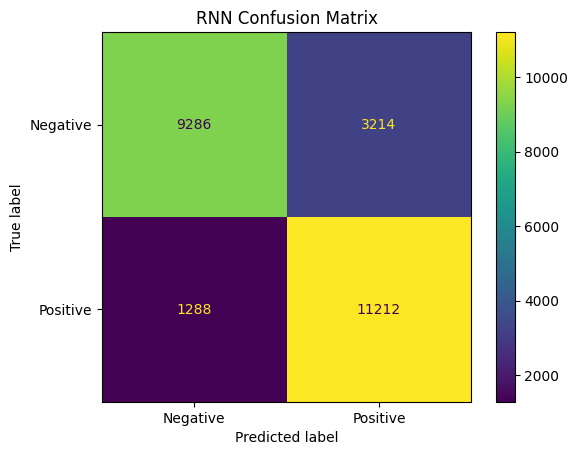

In [18]:
cm = confusion_matrix(y_test, rnn_predictions)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"],
)
disp.plot()
plt.title("RNN Confusion Matrix")
plt.show()

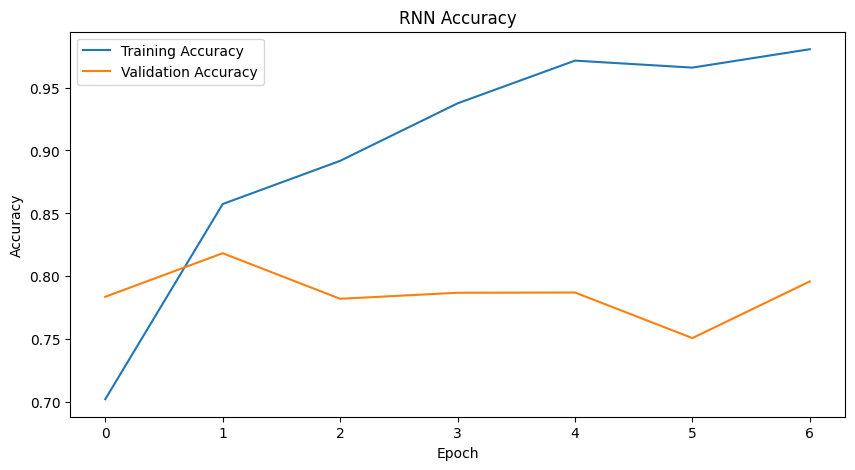

In [19]:
plt.figure(figsize=(10, 5))
plt.plot(rnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(rnn_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("RNN Accuracy")
plt.legend()
plt.show()

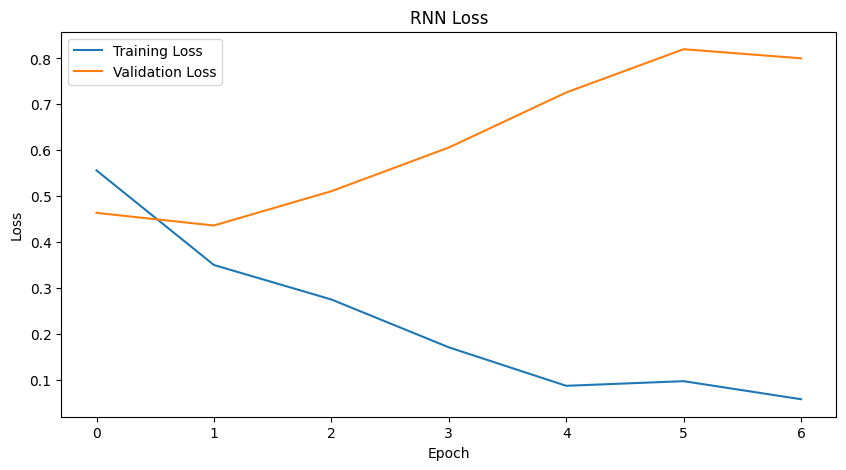

In [20]:
plt.figure(figsize=(10, 5))
plt.plot(rnn_history.history["loss"], label="Training Loss")
plt.plot(rnn_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RNN Loss")
plt.legend()
plt.show()

## 10. LSTM
Same architecture with an LSTM layer.

In [21]:
def build_lstm_model():
    model = Sequential([
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIM,
        ),
        LSTM(RNN_UNITS),
        Dropout(0.5),
        Dense(1, activation="sigmoid"),
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [22]:
lstm_model = build_lstm_model()
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [23]:
start_time = time.time()
lstm_history = lstm_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[make_early_stopping()],
    verbose=1,
)
lstm_training_time = time.time() - start_time
print(f"Training time: {lstm_training_time:.2f} seconds")

Epoch 1/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.7481 - loss: 0.4941 - val_accuracy: 0.8614 - val_loss: 0.3359
Epoch 2/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8891 - loss: 0.2793 - val_accuracy: 0.8548 - val_loss: 0.3758
Epoch 3/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9148 - loss: 0.2237 - val_accuracy: 0.8692 - val_loss: 0.3315
Epoch 4/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9316 - loss: 0.1875 - val_accuracy: 0.8658 - val_loss: 0.3850
Epoch 5/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9488 - loss: 0.1463 - val_accuracy: 0.8350 - val_loss: 0.4197
Epoch 6/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9478 - loss: 0.1434 - val_accuracy: 0.8460 - val_loss: 0.4260
Epoch 7/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9585 - loss: 0.1169 - val_accuracy: 0.8424 - val_loss: 0.5325
Epoch 8/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9683 - loss: 0.0940 - val_acc

In [24]:
lstm_probabilities = lstm_model.predict(X_test_pad)
lstm_predictions = (lstm_probabilities >= 0.5).astype(int).flatten()

lstm_accuracy  = accuracy_score(y_test, lstm_predictions)
lstm_precision = precision_score(y_test, lstm_predictions)
lstm_recall    = recall_score(y_test, lstm_predictions)
lstm_f1        = f1_score(y_test, lstm_predictions)

print("LSTM Results")
print("-" * 30)
print("Accuracy :", lstm_accuracy)
print("Precision:", lstm_precision)
print("Recall   :", lstm_recall)
print("F1 Score :", lstm_f1)

782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step
LSTM Results
------------------------------
Accuracy : 0.86052
Precision: 0.8925180733385594
Recall   : 0.81976
F1 Score : 0.8545932196322088


In [25]:
print(
    classification_report(
        y_test,
        lstm_predictions,
        target_names=["Negative", "Positive"],
    )
)

              precision    recall  f1-score   support

    Negative       0.83      0.90      0.87     12500
    Positive       0.89      0.82      0.85     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     25000
weighted avg       0.86      0.86      0.86     25000



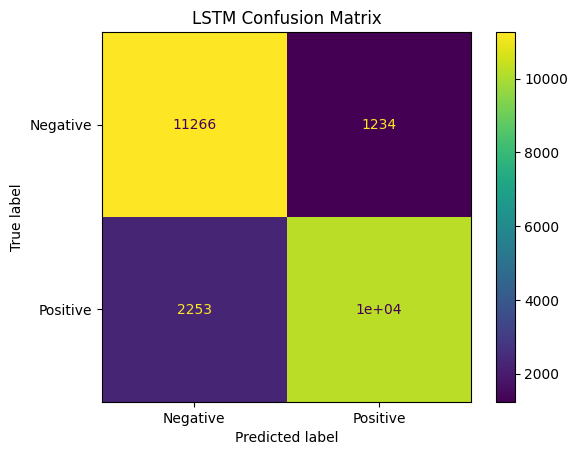

In [26]:
cm = confusion_matrix(y_test, lstm_predictions)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"],
)
disp.plot()
plt.title("LSTM Confusion Matrix")
plt.show()

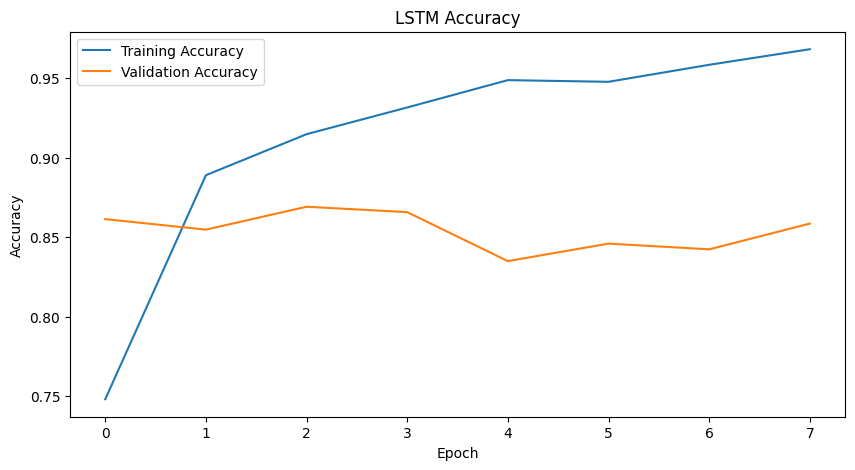

In [27]:
plt.figure(figsize=(10, 5))
plt.plot(lstm_history.history["accuracy"], label="Training Accuracy")
plt.plot(lstm_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Accuracy")
plt.legend()
plt.show()

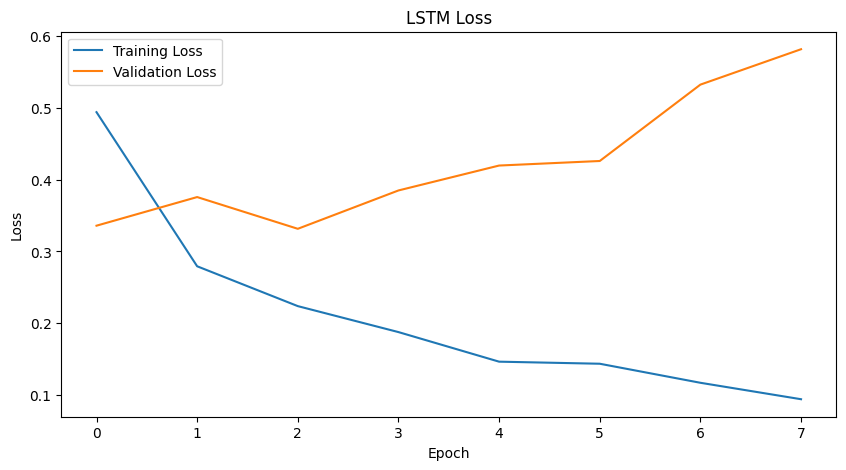

In [28]:
plt.figure(figsize=(10, 5))
plt.plot(lstm_history.history["loss"], label="Training Loss")
plt.plot(lstm_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Loss")
plt.legend()
plt.show()

## 11. GRU
Same architecture with a GRU layer.

In [29]:
def build_gru_model():
    model = Sequential([
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIM,
        ),
        GRU(RNN_UNITS),
        Dropout(0.5),
        Dense(1, activation="sigmoid"),
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [30]:
gru_model = build_gru_model()
gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [31]:
start_time = time.time()
gru_history = gru_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[make_early_stopping()],
    verbose=1,
)
gru_training_time = time.time() - start_time
print(f"Training time: {gru_training_time:.2f} seconds")

Epoch 1/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.7321 - loss: 0.5151 - val_accuracy: 0.8520 - val_loss: 0.3529
Epoch 2/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8960 - loss: 0.2676 - val_accuracy: 0.8572 - val_loss: 0.3452
Epoch 3/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9251 - loss: 0.1996 - val_accuracy: 0.8666 - val_loss: 0.3452
Epoch 4/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9425 - loss: 0.1563 - val_accuracy: 0.8546 - val_loss: 0.4099
Epoch 5/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9613 - loss: 0.1095 - val_accuracy: 0.8552 - val_loss: 0.4259
Epoch 6/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9783 - loss: 0.0683 - val_accuracy: 0.8526 - val_loss: 0.5140
Epoch 7/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9826 - loss: 0.0560 - val_accuracy: 0.8634 - val_loss: 0.5321
Epoch 8/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9845 - loss: 0.0472 - val_accu

In [32]:
gru_probabilities = gru_model.predict(X_test_pad)
gru_predictions = (gru_probabilities >= 0.5).astype(int).flatten()

gru_accuracy  = accuracy_score(y_test, gru_predictions)
gru_precision = precision_score(y_test, gru_predictions)
gru_recall    = recall_score(y_test, gru_predictions)
gru_f1        = f1_score(y_test, gru_predictions)

print("GRU Results")
print("-" * 30)
print("Accuracy :", gru_accuracy)
print("Precision:", gru_precision)
print("Recall   :", gru_recall)
print("F1 Score :", gru_f1)

782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step
GRU Results
------------------------------
Accuracy : 0.86068
Precision: 0.8346819092866157
Recall   : 0.89952
F1 Score : 0.8658888760540603


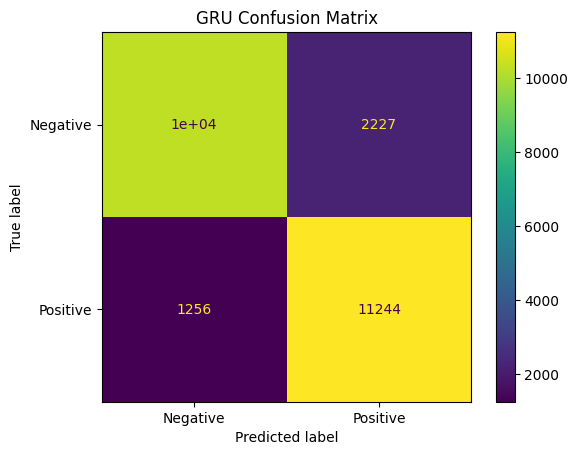

In [33]:
cm = confusion_matrix(y_test, gru_predictions)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"],
)
disp.plot()
plt.title("GRU Confusion Matrix")
plt.show()

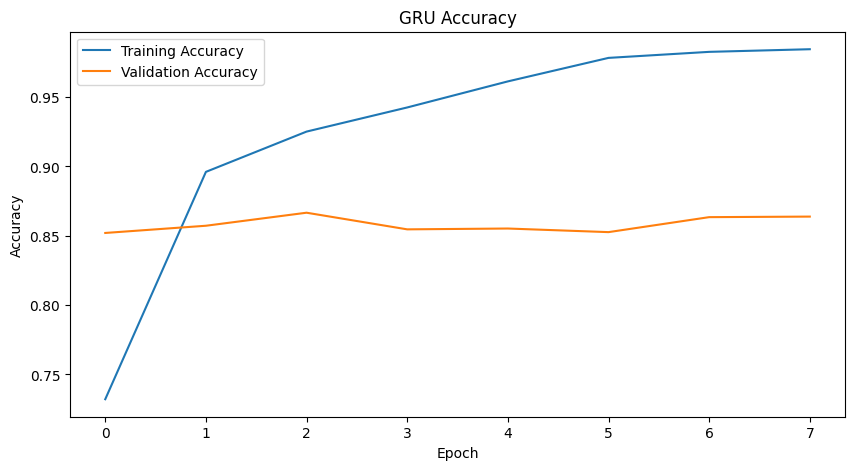

In [34]:
plt.figure(figsize=(10, 5))
plt.plot(gru_history.history["accuracy"], label="Training Accuracy")
plt.plot(gru_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("GRU Accuracy")
plt.legend()
plt.show()

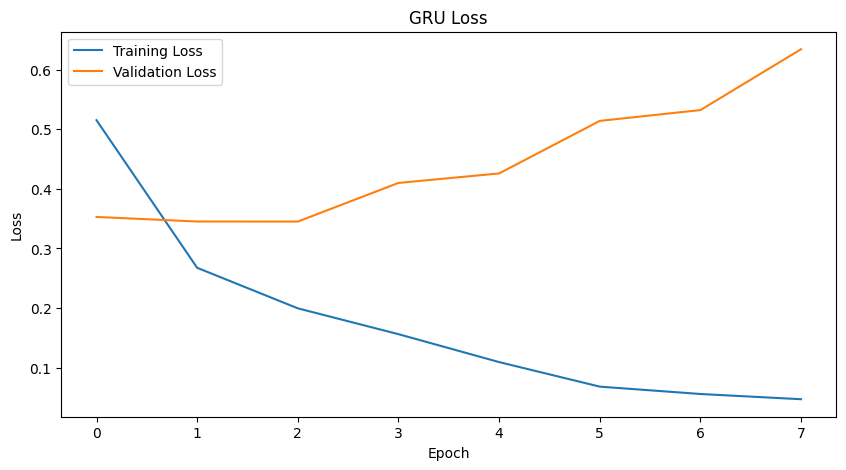

In [35]:
plt.figure(figsize=(10, 5))
plt.plot(gru_history.history["loss"], label="Training Loss")
plt.plot(gru_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GRU Loss")
plt.legend()
plt.show()

## 12. Baseline: TF-IDF + Logistic Regression
A classical model on the same data (word IDs treated as tokens, unigrams + bigrams). If a deep model cannot beat this, its extra cost is hard to justify.

In [36]:
def ids_to_text(sequences):
    return [" ".join(map(str, s)) for s in sequences]

start_time = time.time()
tfidf = TfidfVectorizer(token_pattern=r"\S+", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(ids_to_text(X_train))
X_test_tfidf = tfidf.transform(ids_to_text(X_test))

baseline = LogisticRegression(max_iter=2000, C=4, random_state=RANDOM_STATE)
baseline.fit(X_train_tfidf, y_train)
baseline_training_time = time.time() - start_time

baseline_predictions = baseline.predict(X_test_tfidf)
baseline_accuracy  = accuracy_score(y_test, baseline_predictions)
baseline_precision = precision_score(y_test, baseline_predictions)
baseline_recall    = recall_score(y_test, baseline_predictions)
baseline_f1        = f1_score(y_test, baseline_predictions)

print("TF-IDF + Logistic Regression")
print("-" * 30)
print("Accuracy :", baseline_accuracy)
print("Precision:", baseline_precision)
print("Recall   :", baseline_recall)
print("F1 Score :", baseline_f1)
print(f"Training time: {baseline_training_time:.2f} seconds")

TF-IDF + Logistic Regression
------------------------------
Accuracy : 0.90796
Precision: 0.9053334393132502
Recall   : 0.9112
F1 Score : 0.908257246521271
Training time: 30.48 seconds


## 13. Bidirectional LSTM
The LSTM reads each review forwards and backwards.

In [37]:
def build_bilstm_model():
    model = Sequential([
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIM,
        ),
        Bidirectional(LSTM(RNN_UNITS)),
        Dropout(0.5),
        Dense(1, activation="sigmoid"),
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model

bilstm_model = build_bilstm_model()

start_time = time.time()
bilstm_history = bilstm_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[make_early_stopping()],
    verbose=1,
)
bilstm_training_time = time.time() - start_time
print(f"Training time: {bilstm_training_time:.2f} seconds")

Epoch 1/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 18s 42ms/step - accuracy: 0.7692 - loss: 0.4836 - val_accuracy: 0.8364 - val_loss: 0.3817
Epoch 2/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.8849 - loss: 0.2888 - val_accuracy: 0.8658 - val_loss: 0.3279
Epoch 3/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.9198 - loss: 0.2176 - val_accuracy: 0.8546 - val_loss: 0.3603
Epoch 4/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.9129 - loss: 0.2250 - val_accuracy: 0.7968 - val_loss: 0.4704
Epoch 5/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.8813 - loss: 0.2945 - val_accuracy: 0.8534 - val_loss: 0.3848
Epoch 6/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9426 - loss: 0.1569 - val_accuracy: 0.8608 - val_loss: 0.4328
Epoch 7/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9639 - loss: 0.1061 - val_accuracy: 0.8398 - val_loss: 0.4560
Training time: 65.32 seconds


In [38]:
bilstm_probabilities = bilstm_model.predict(X_test_pad)
bilstm_predictions = (bilstm_probabilities >= 0.5).astype(int).flatten()

bilstm_accuracy  = accuracy_score(y_test, bilstm_predictions)
bilstm_precision = precision_score(y_test, bilstm_predictions)
bilstm_recall    = recall_score(y_test, bilstm_predictions)
bilstm_f1        = f1_score(y_test, bilstm_predictions)

print("BiLSTM Results")
print("-" * 30)
print("Accuracy :", bilstm_accuracy)
print("Precision:", bilstm_precision)
print("Recall   :", bilstm_recall)
print("F1 Score :", bilstm_f1)
print()
print(classification_report(y_test, bilstm_predictions, target_names=["Negative", "Positive"]))

782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step
BiLSTM Results
------------------------------
Accuracy : 0.86296
Precision: 0.8409227532311392
Recall   : 0.89528
F1 Score : 0.8672504649721017

              precision    recall  f1-score   support

    Negative       0.89      0.83      0.86     12500
    Positive       0.84      0.90      0.87     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     25000
weighted avg       0.86      0.86      0.86     25000



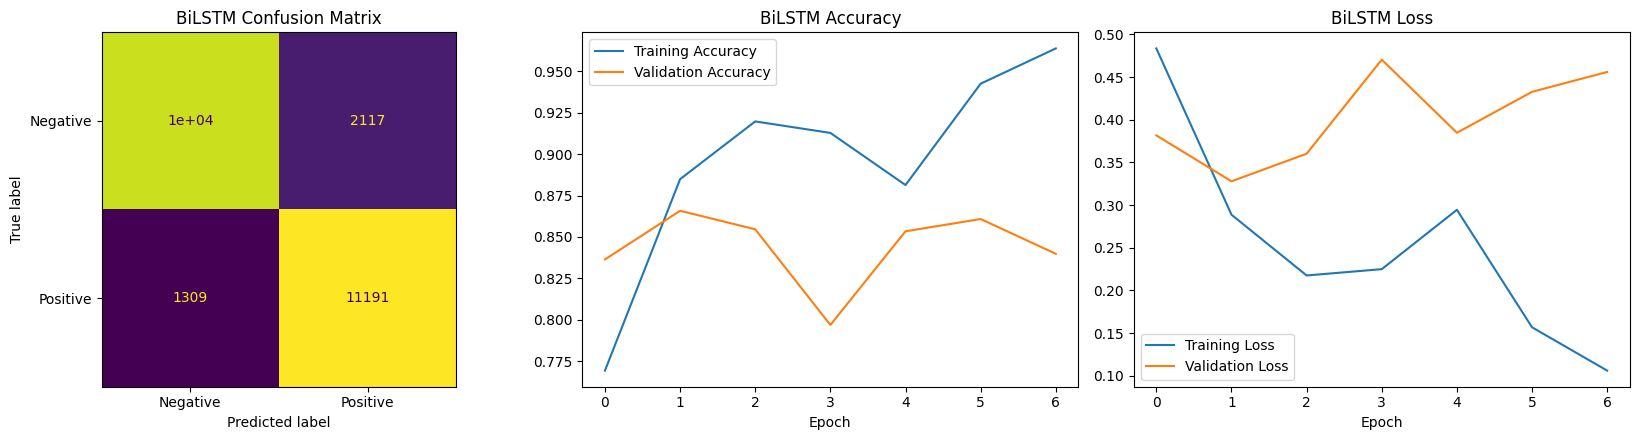

In [39]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ConfusionMatrixDisplay(confusion_matrix(y_test, bilstm_predictions),
                       display_labels=["Negative", "Positive"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title("BiLSTM Confusion Matrix")

ax[1].plot(bilstm_history.history["accuracy"], label="Training Accuracy")
ax[1].plot(bilstm_history.history["val_accuracy"], label="Validation Accuracy")
ax[1].set_title("BiLSTM Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()

ax[2].plot(bilstm_history.history["loss"], label="Training Loss")
ax[2].plot(bilstm_history.history["val_loss"], label="Validation Loss")
ax[2].set_title("BiLSTM Loss"); ax[2].set_xlabel("Epoch"); ax[2].legend()

plt.tight_layout(); plt.show()

## 14. Compare all models

In [40]:
results = pd.DataFrame({
    "Model": ["Simple RNN", "LSTM", "GRU", "BiLSTM", "TF-IDF + LogReg"],   # CHANGED: 5 models

    "Accuracy":  [rnn_accuracy,  lstm_accuracy,  gru_accuracy,  bilstm_accuracy,  baseline_accuracy],
    "Precision": [rnn_precision, lstm_precision, gru_precision, bilstm_precision, baseline_precision],
    "Recall":    [rnn_recall,    lstm_recall,    gru_recall,    bilstm_recall,    baseline_recall],
    "F1 Score":  [rnn_f1,        lstm_f1,        gru_f1,        bilstm_f1,        baseline_f1],

    "Training Time (sec)": [
        rnn_training_time,
        lstm_training_time,
        gru_training_time,
        bilstm_training_time,
        baseline_training_time,
    ],
})
results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (sec)
0,Simple RNN,0.8199,0.7772,0.8970,0.8328,59.9598
1,LSTM,0.8605,0.8925,0.8198,0.8546,41.3662
2,GRU,0.8607,0.8347,0.8995,0.8659,35.3398
3,BiLSTM,0.8630,0.8409,0.8953,0.8673,65.3186
4,TF-IDF + LogReg,0.9080,0.9053,0.9112,0.9083,30.4760


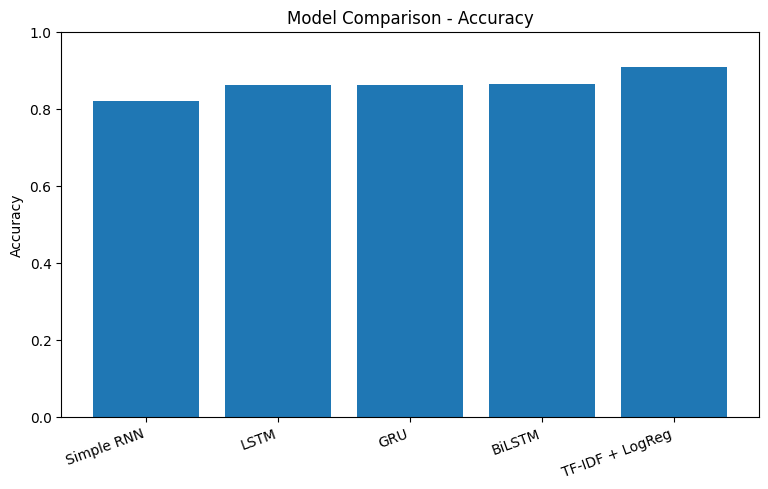

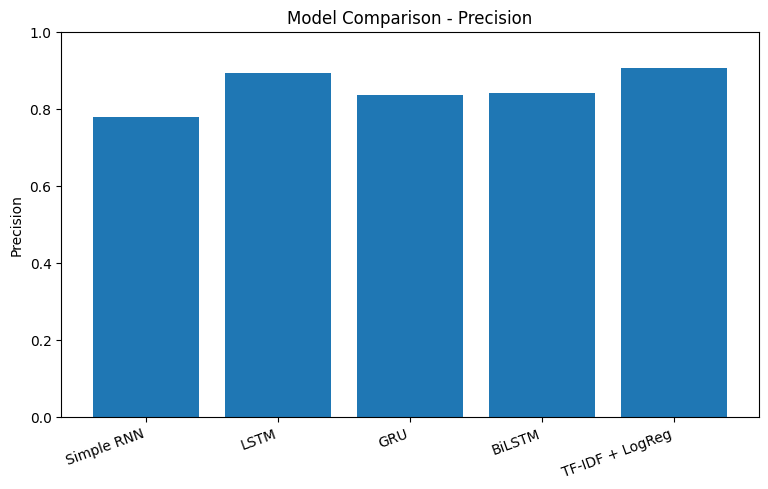

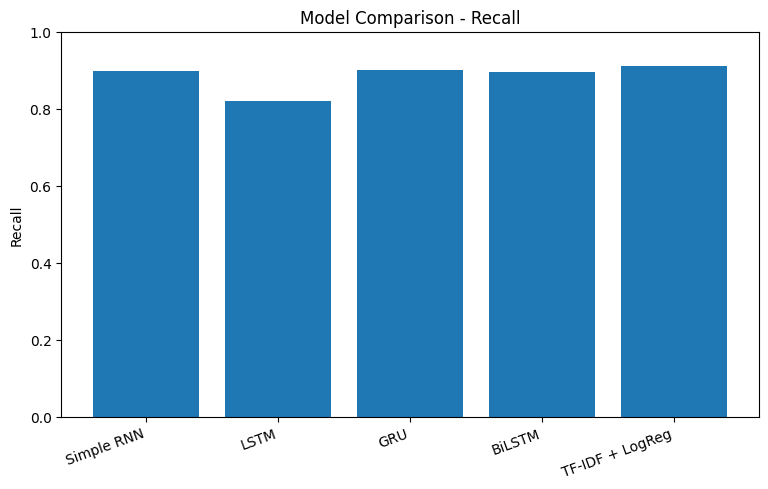

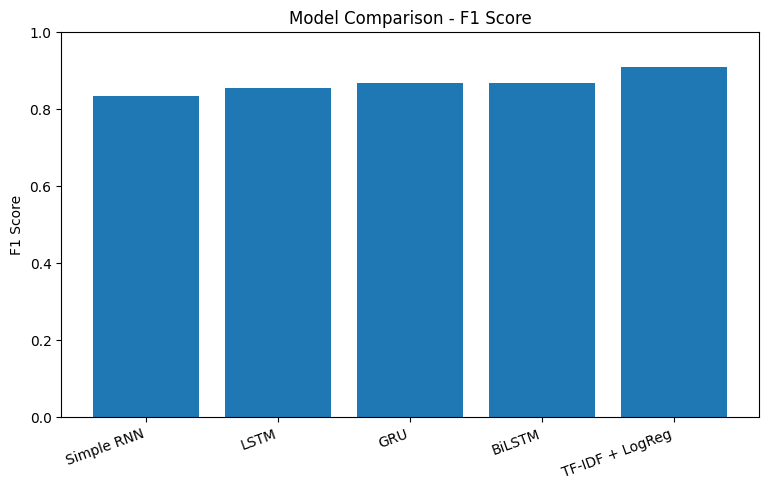

In [41]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

for metric in metrics:
    plt.figure(figsize=(9, 5))
    plt.bar(results["Model"], results[metric])
    plt.ylabel(metric)
    plt.title(f"Model Comparison - {metric}")
    plt.ylim(0, 1)
    plt.xticks(rotation=20, ha='right')
    plt.show()

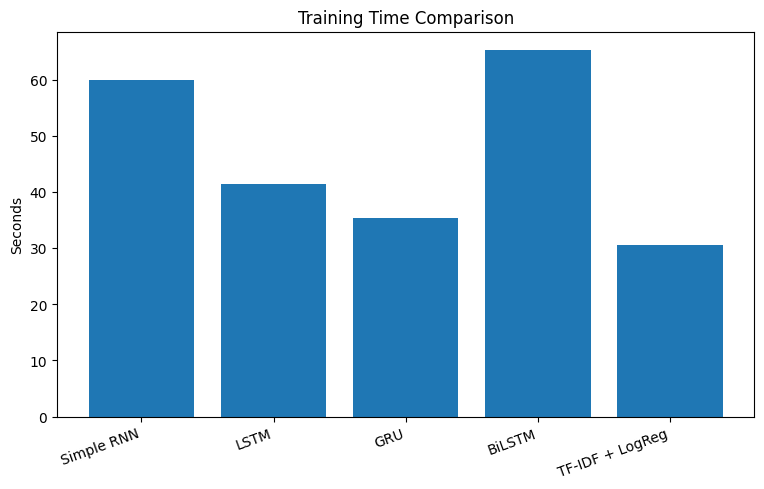

In [42]:
plt.figure(figsize=(9, 5))
plt.bar(results["Model"], results["Training Time (sec)"])
plt.ylabel("Seconds")
plt.title("Training Time Comparison")
plt.xticks(rotation=20, ha='right')
plt.show()

### Observations

- **The TF-IDF + Logistic Regression baseline is the best model** (accuracy 0.908, F1 0.908). Every deep model scored lower; the best, BiLSTM, reached 0.863 accuracy and 0.867 F1.
- **BiLSTM, GRU and LSTM are practically tied** (accuracy 0.861-0.863, F1 0.855-0.867); Simple RNN is clearly weaker (accuracy 0.820, F1 0.833). In an earlier run of the same code the LSTM was the top deep model and GRU scored 0.846, so the ranking among the three is within run-to-run noise. The baseline gave exactly the same result in both runs.
- **All deep models overfit quickly:** the best validation loss appeared in epoch 2-3 while training accuracy kept climbing to 96-98%. EarlyStopping restored the best weights, but the models memorize the training reviews (the Simple RNN validation loss rose from 0.44 to 0.82).
- **Training times depend on the hardware:** in this run the deep models took 35-65 s and the baseline about 30 s; in an earlier run on slower hardware the deep models took 200-850 s. Either way the baseline is at least as cheap as the neural networks.
- **Plausible reasons the baseline wins** (not tested here): bigrams capture phrases such as "not good", it reads the whole review while the networks see only 200 tokens, and the networks learn embeddings from scratch on just 20,000 reviews.

## 15. Test on new reviews
New text is encoded exactly like the training data: `<START>` first, IDs shifted by +3, unknown or out-of-vocabulary words mapped to `<UNK>`.

In [43]:
def encode_new_review(text):
    words = re.findall(r"[a-z']+", text.lower())
    encoded = [1]
    for word in words:
        idx = word_index.get(word)
        if idx is None or idx + 3 >= VOCAB_SIZE:
            encoded.append(2)
        else:
            encoded.append(idx + 3)

    return pad_sequences(
        [encoded],
        maxlen=MAX_LENGTH,
        padding="pre",
        truncating="pre",
    )

In [44]:
def predict_sentiment(model, text):
    encoded_text = encode_new_review(text)
    probability = model.predict(encoded_text, verbose=0)[0][0]

    if probability >= 0.5:
        sentiment = "Positive"
        confidence = probability
    else:
        sentiment = "Negative"
        confidence = 1 - probability

    return sentiment, confidence

In [45]:
reviews = [
    "This movie was absolutely amazing and I loved it",
    "This movie was terrible and boring",
    "I really enjoyed this film",
    "The movie was not good and I hated it",
    "I would not recommend this film, a complete waste of time",
]
for review in reviews:
    print("\nReview:", review)
    for name, model in [
        ("RNN", rnn_model),
        ("LSTM", lstm_model),
        ("GRU", gru_model),
        ("BiLSTM", bilstm_model),
    ]:
        sentiment, confidence = predict_sentiment(model, review)
        print(f"{name}: {sentiment} ({confidence:.2%})")


Review: This movie was absolutely amazing and I loved it
RNN: Positive (97.14%)
LSTM: Positive (96.47%)
GRU: Positive (97.15%)
BiLSTM: Positive (96.87%)

Review: This movie was terrible and boring
RNN: Negative (76.73%)
LSTM: Negative (95.83%)
GRU: Negative (94.19%)
BiLSTM: Negative (84.91%)

Review: I really enjoyed this film
RNN: Positive (91.68%)
LSTM: Positive (80.76%)
GRU: Positive (89.84%)
BiLSTM: Positive (91.07%)

Review: The movie was not good and I hated it
RNN: Positive (66.93%)
LSTM: Negative (52.45%)
GRU: Negative (59.95%)
BiLSTM: Positive (70.12%)

Review: I would not recommend this film, a complete waste of time
RNN: Negative (85.82%)
LSTM: Negative (97.64%)
GRU: Negative (97.71%)
BiLSTM: Negative (89.18%)


## 16. Error analysis
Reviews the best deep model (chosen automatically by F1; BiLSTM in this run) got wrong.

In [46]:
test_texts = [
    decode_review(X_test[i])
    for i in range(len(X_test))
]

deep_predictions = {
    "Simple RNN": rnn_predictions, "LSTM": lstm_predictions,
    "GRU": gru_predictions, "BiLSTM": bilstm_predictions,
}
best_deep = max(deep_predictions, key=lambda n: f1_score(y_test, deep_predictions[n]))
best_preds = deep_predictions[best_deep]
print("Best deep model:", best_deep)

error_indices = np.where(best_preds != y_test)[0]
print("Number of errors:", len(error_indices))

Best deep model: BiLSTM
Number of errors: 3426


In [47]:
for i in error_indices[:10]:
    print("=" * 80)
    print("Review:")
    print(test_texts[i][:1000])

    print("\nActual:",    "Positive" if y_test[i] == 1 else "Negative")
    print("Predicted:", "Positive" if best_preds[i] == 1 else "Negative")

Review:
<START> i generally love this type of movie however this time i found myself wanting to kick the screen since i can't do that i will just complain about it this was absolutely idiotic the things that happen with the dead kids are very cool but the alive people are absolute idiots i am a grown man pretty big and i can defend myself well however i would not do half the stuff the little girl does in this movie also the mother in this movie is reckless with her children to the point of neglect i wish i wasn't so angry about her and her actions because i would have otherwise enjoyed the flick what a number she was take my advise and fast forward through everything you see her do until the end also is anyone else getting sick of watching movies that are filmed so dark anymore one can hardly see what is being filmed as an audience we are <UNK> involved with the actions on the screen so then why the hell can't we have night vision

Actual: Negative
Predicted: Positive
Review:
<START> h

## 17. Conclusions

- A strong classical baseline beat all four recurrent models on this task, so deep learning was not worth its cost here. It is essential to run a baseline before claiming a neural model is better.
- **Preprocessing mattered more than architecture:** with `post` padding, Simple RNN and GRU stayed at chance level; with `pre` padding and a longer patience they trained properly.
- **Single-run comparisons between similar neural models are unreliable.** The same code gave different rankings in two runs, so differences of one or two points should be confirmed by averaging several runs or seeds.
- **Negation is fragile.** For "The movie was not good and I hated it", Simple RNN and BiLSTM predicted positive, while LSTM and GRU got it right with only about 52% and 60% confidence.
- The best deep model (BiLSTM) made 3,426 errors on 25,000 test reviews (13.7%). The reviews it misses are mostly long, mix praise with criticism, or contain many `<UNK>` tokens.
- **Next steps:** stronger regularization (embedding dropout, recurrent dropout, smaller embedding), pretrained embeddings such as GloVe, longer sequences, averaging several seeds, or fine-tuning a transformer like DistilBERT.